# Optimización Bayesiana

In [81]:
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

**Teorema de Bayes**

$$ P(A|B) = \frac{P(B|A) P(A)}{P(B)} $$

$ P(A|B) $: Probabilidad condicional de A dado B. También conocida como la probabilidad posterior de A dado que B ocurre.

$ P(B|A) $: Probabilidad condicional de B dado A. Se interpreta como la verosimilitud (*likelihood*) de A.

$ P(A) $: Probabilidad de observar A. También conocida como probabilidad a priori.

$ P(B) $: Probabilidad de observar B. Interpretada como evidencia.

Utilizando las definiciones de arriba actualizamos la definición del teorema de bayes:

$$ \text{posterior} = \frac{(\text{verosimilitud})(\text{anterior})}{\text{evidencia}} $$

La intuición es que el teorema de Bayes es una herramienta para actualizar nuestras creencias dado lo que se tenía antes y nueva evidencia. Por ejemplo, tomas una moneda y asumes que es una moneda justa, dado que es lo más probable y que las monedas suelen ser justas en tu experiencia. Lanzas la moneda tres veces y cae sello las tres veces; un poco extraño, así que ajustas tus creencias y empiezas a imaginar que la moneda no es tan justa como debería ser. Lanzas las monedas tres veces y cae águila; ahora crees que la moneda es justa de nuevo.

## ¿Cómo aplicamos esto en nuestra vida diaria?

Imagina que tienes 3 puntos (conocimiento previo) en un espacio.

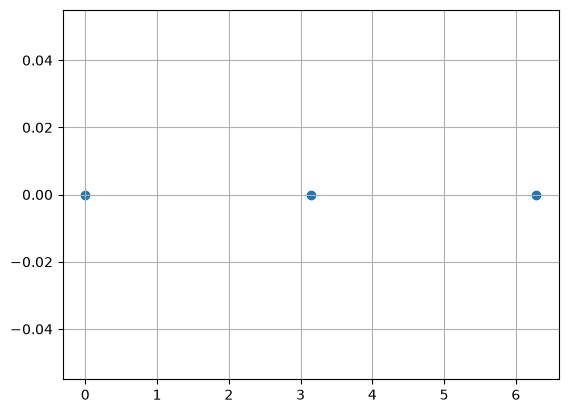

In [82]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
plt.figure(); plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0]); plt.grid()

No hay seguridad de cómo se conectan estos puntos, pero sabes que están conectados. Hay infinitas formas en las que estos puntos se pueden conectar.

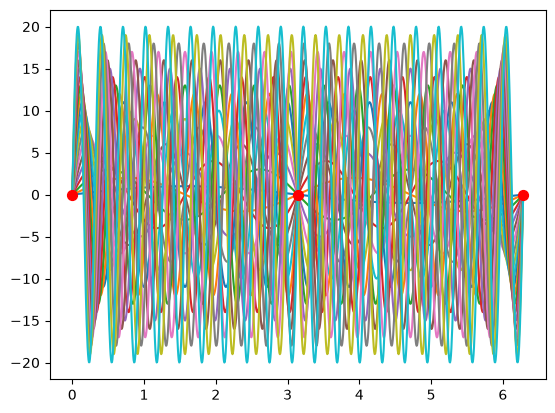

In [83]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(20) :
    y = (i+1)*np.sin((i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi], [0, 0, 0], s=50, c="r", zorder=3)

Hay tanta incertidumbre que decides pedir más información y te dan otro punto.

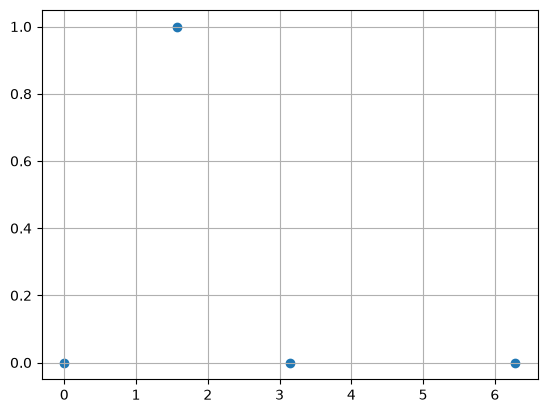

In [84]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1]); plt.grid()

Con esta nueva información actualizas tus creencias y reduces la cantidad de formas en las que se conectan estos puntos (siguen siendo infinitas).

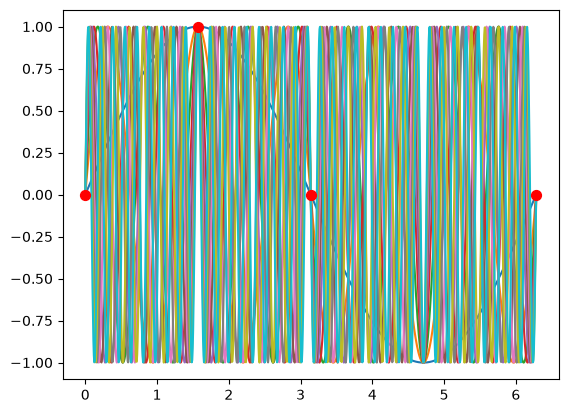

In [85]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(10) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Te pones a pensar: "Sí. Teóricamente hay infinitas funciones que pueden conectar estos puntos, pero sólo algunas tienen sentido dado mi contexto."

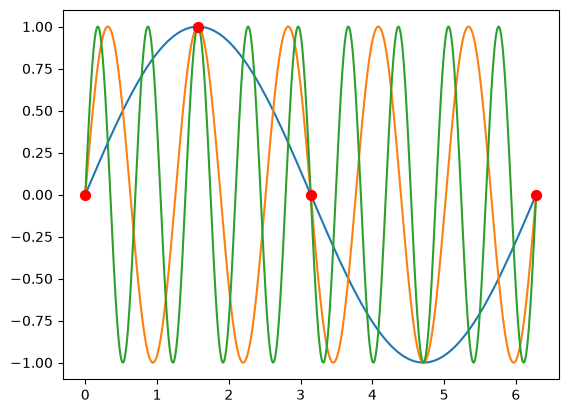

In [86]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); 
for i in range(3) :
    y = np.sin((4*i+1)*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2], [0, 0, 0, 1], s=50, c="r", zorder=3)

Ahora sólo quedan algunos pocos candidatos dado el criterio que tienes. Hay incertidumbre sobre cuál de estos candidatos podría ser el que mejor se ajusta, así que decides pedir más información. ¿Qué información serviría más?
- Se podría pedir el valor de $y$ cuando $x=\frac{3\pi}{2}$, pero los candidatos que tenemos todos pasan por el mismo punto. Incluso si nos dieran la información, no ayudaría de mucho.
- Se podría pedir fuera del rango que tenemos, pero quizás la información no existe o dado el contexto del problema es imposible que estos puntos existan.

Nos asignan nuestro último punto.

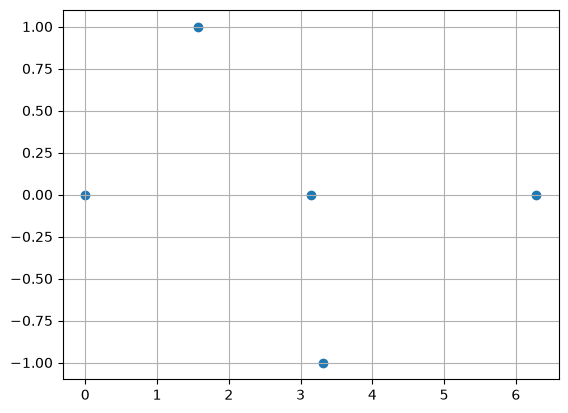

In [87]:
plt.figure(); plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1]); plt.grid()

Usamos esta nueva información (evidencia) junto con lo que conocíamos (anterior) y lo que creemos que es posible (verosimilitud) para decidir sobre una nueva función (posterior).

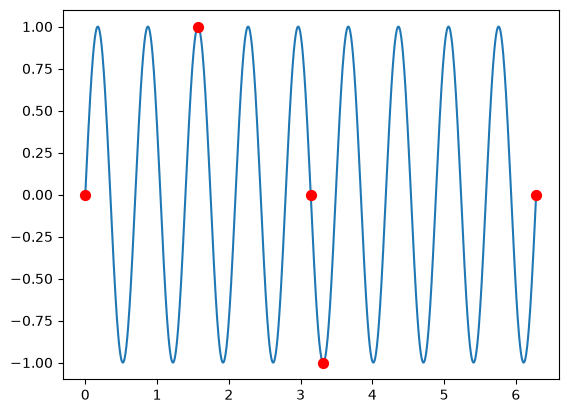

In [88]:
x = np.linspace(0, 2*np.pi, 1000); plt.figure(); y = np.sin(9*x); plt.plot(x, y)
plt.scatter([0, np.pi, 2*np.pi, np.pi/2, 19*np.pi/18], [0, 0, 0, 1, -1], s=50, c="r", zorder=3)

Una forma de realizar este experimento es mediante un proceso gaussiano, que asume que la variable de salida es una variable aleatoria con distribución normal multivariada. Utilicemos la función que encontramos y asumamos que no sabemos cuál es.

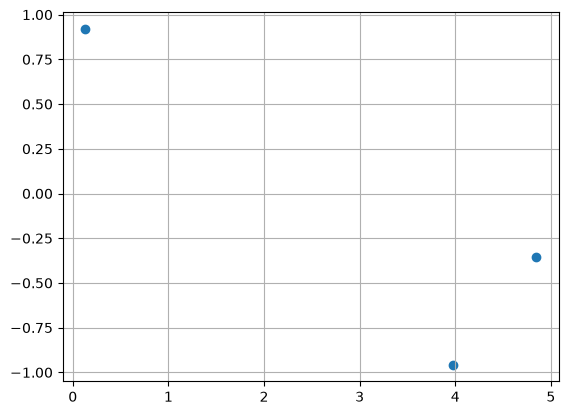

In [89]:
np.random.seed(10)
def f(x) :
    return np.sin(9*x)
X = np.random.uniform(0, 2*np.pi, 3).reshape([-1, 1])
plt.figure(); plt.scatter(X, f(X)); plt.grid()

Realizamos una regresión de proceso gaussiano para encontrar distribuciones que podrían darnos estas muestras

In [90]:
kernel = 1* RBF (length_scale=1)
gp= GaussianProcessRegressor(kernel=kernel, n_restarts_optimizer=10)

y=f(X)
gp.fit(X,y)

,"kernel kernel: kernel instance, default=NoneThe kernel specifying the covariance function of the GP.If `None` is passed,the kernel `ConstantKernel() * RBF()` is used as default.Note thatthe kernel hyperparameters are optimized during fittingunless the bounds are marked as `""fixed""`or the argument `optimizer` is set to `None`.",1**2 * RBF(length_scale=1)
,"n_restarts_optimizer n_restarts_optimizer: int, default=0The number of restarts of the optimizer for finding the kernel'sparameters which maximize the log-marginal likelihood. The first runof the optimizer is performed from the kernel's initial parameters,the remaining ones (if any) from thetas sampled log-uniform randomlyfrom the space of allowed theta-values. If greater than 0, all boundsmust be finite. Note that `n_restarts_optimizer == 0` implies that onerun is performed.",10
,kernel__k1,1**2
,kernel__k2,RBF(length_scale=1)
,kernel__k1__constant_value,1
,kernel__k1__constant_value_bounds,"(1e-05, ...)"
,kernel__k2__length_scale,1
,kernel__k2__length_scale_bounds,"(1e-05, ...)"
,"alpha alpha: float or ndarray of shape (n_samples,), default=1e-10Value added to the diagonal of the kernel matrix during fitting.This can prevent a potential numerical issue during fitting, byensuring that the calculated values form a positive definite matrix.It can also be interpreted as the variance of additional Gaussianmeasurement noise on the training observations. Note that this isdifferent from using a `WhiteKernel`. If an array is passed, it musthave the same number of entries as the data used for fitting and isused as datapoint-dependent noise level. Allowing to specify thenoise level directly as a parameter is mainly for convenience andfor consistency with :class:`~sklearn.linear_model.Ridge`.For an example illustrating how the alpha parameter controlsthe noise variance in Gaussian Process Regression, see:ref:`sphx_glr_auto_examples_gaussian_process_plot_gpr_noisy_targets.py`.",1e-10
,"optimizer optimizer: ""fmin_l_bfgs_b"", callable or None, default=""fmin_l_bfgs_b""Can either be one of the internally supported optimizers for optimizingthe kernel's parameters, specified by a string, or an externallydefined optimizer passed as a callable. If a callable is passed, itmust have the signature:: def optimizer(obj_func, initial_theta, bounds): # * 'obj_func': the objective function to be minimized, which # takes the hyperparameters theta as a parameter and an # optional flag eval_gradient, which determines if the # gradient is returned additionally to the function value # * 'initial_theta': the initial value for theta, which can be # used by local optimizers # * 'bounds': the bounds on the values of theta .... # Returned are the best found hyperparameters theta and # the corresponding value of the target function. return theta_opt, func_minPer default, the L-BFGS-B algorithm from `scipy.optimize.minimize`is used. If None is passed, the kernel's parameters are kept fixed.Available internal optimizers are: `{'fmin_l_bfgs_b'}`.",'fmin_l_bfgs_b'
,"normalize_y normalize_y: bool, default=FalseWhether or not to normalize the target values `y` by removing the meanand scaling to unit-variance. This is recommended for cases wherezero-mean, unit-variance priors are used. Note that, in thisimplementation, the normalisation is reversed before the GP predictionsare reported... versionchanged:: 0.23",False


Creamos un vector de valores posibles de $x$ y predecimos $y$ usando el resultado de la regresión.

In [91]:
X_new = np.linspace(0,2*np.pi,10000).reshape(-1,1)
y_pred, desv = gp.predict(X_new, return_std=True)

Graficamos nuestra primera propuesta, utilizando el error estándar para dibujar nuestros intervalos de confianza.

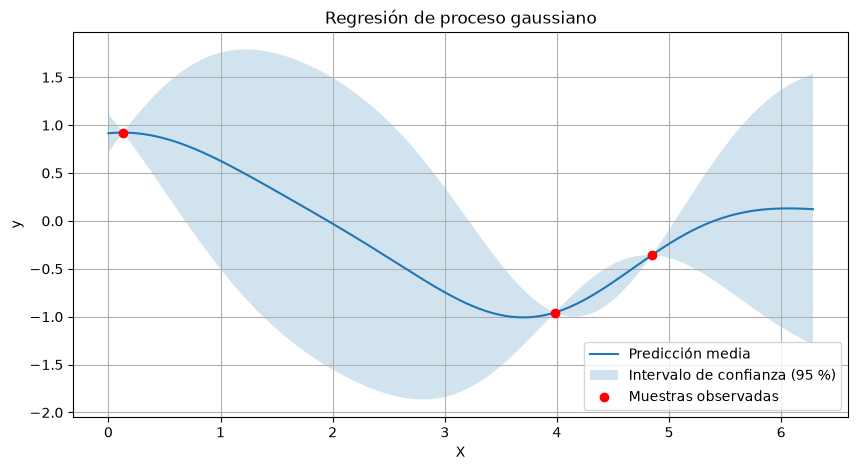

In [92]:
plt.figure(figsize=(10, 5))
plt.plot(X_new.ravel(), y_pred, label="Predicción media")
plt.fill_between(
    X_new.ravel(),
    y_pred - 1.96 * desv,
    y_pred + 1.96 * desv,
    alpha=0.2,
    label="Intervalo de confianza (95 %)"
)
plt.scatter(X.ravel(), y.ravel(), color="red", zorder=3, label="Muestras observadas")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Regresión de proceso gaussiano")
plt.grid(True)
plt.legend()
plt.show()

Podemos ver que necesitamos más muestras debido a que hay mucha incertidumbre en algunas partes de nuestro dominio. Hay varios criterios para decidir cómo pedir muestras:
- Maximizar (busco mi predicción del máximo actual y pido esa medida)
- Minimizar (busco mi predicción del mínimo actual y pido esa medida)
- Reducir incertidumbre (busco el punto donde mi intervalo de confianza es más grande y pido esa medida)

In [93]:
y_upper = y_pred + 2*desv
y_lower = y_pred - 2*desv

Y repetimos el proceso ya con nueva información.

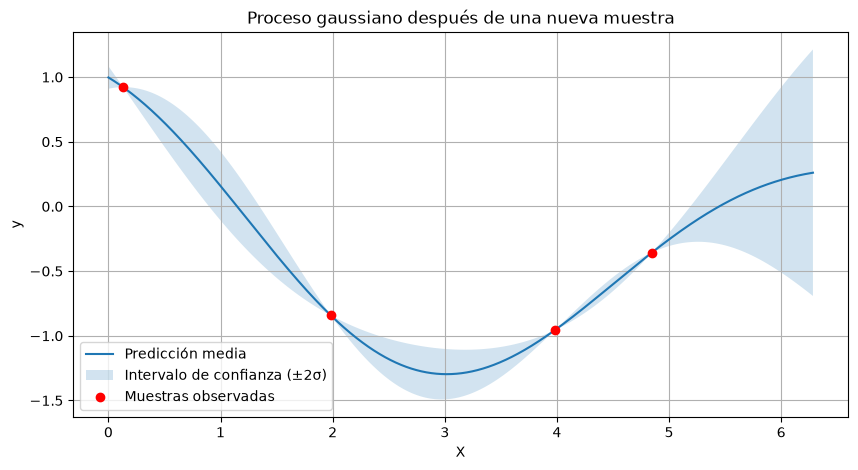

Nueva muestra: x = 1.9832, y = -0.8420


In [94]:
# Elegir el punto con mayor incertidumbre
indice = np.argmax(y_upper - y_lower)
X_next = X_new[indice].reshape(1, -1)
y_next = f(X_next)

# Agregar la nueva observación y ajustar el modelo
X = np.vstack((X, X_next))
y = np.vstack((y, y_next))
gp.fit(X, y)

# Actualizar predicción e intervalos
y_pred, desv = gp.predict(X_new, return_std=True)
y_upper = y_pred + 2 * desv
y_lower = y_pred - 2 * desv

# Graficar el resultado actualizado
plt.figure(figsize=(10, 5))
plt.plot(X_new.ravel(), y_pred, label="Predicción media")
plt.fill_between(
    X_new.ravel(), y_lower, y_upper,
    alpha=0.2, label="Intervalo de confianza (±2σ)"
)
plt.scatter(X.ravel(), y.ravel(), color="red", zorder=3, label="Muestras observadas")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Proceso gaussiano después de una nueva muestra")
plt.grid(True)
plt.legend()
plt.show()

print(f"Nueva muestra: x = {X_next[0, 0]:.4f}, y = {y_next[0, 0]:.4f}")

Repitamos el proceso 30 veces con una función distinta.

$$ f(x) = \sin{(\frac{x}{3})} + \cos{(2x)},\ \ \ \ x \in [-5\pi, 5\pi] $$

In [95]:
np.random.seed(67)

def f(x):
    return np.sin(x / 3) + np.cos(2 * x)

X = np.random.uniform(-5 * np.pi, 5 * np.pi, 6).reshape(-1, 1)
y = f(X)

print("Muestras iniciales (x, f(x)):")
print(np.column_stack((X.ravel(), y.ravel())))

Muestras iniciales (x, f(x)):
[[  1.44046515  -0.50430279]
 [ 11.27381292  -1.42717763]
 [  5.83998784   1.56239931]
 [ -5.29069898  -1.38391337]
 [-13.82307272   0.18543071]
 [ -3.57268888  -0.27792734]]


In [96]:
# Repetimos 30 veces seleccionando el punto con mayor incertidumbre

X_new = np.linspace(-5*np.pi, 5*np.pi, 1000).reshape(-1, 1)

for i in range(30):

    gp.fit(X, y)

    y_pred, desv = gp.predict(X_new, return_std=True)

    y_upper = y_pred + 2*desv
    y_lower = y_pred - 2*desv

    indice = np.argmax(y_upper - y_lower)

    X_next = X_new[indice].reshape(1, -1)
    y_next = f(X_next)

    X = np.vstack((X, X_next))
    y = np.vstack((y, y_next))

/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 0 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


In [97]:
# Guardamos los resultados de incertidumbre

X_incertidumbre = X.copy()
y_incertidumbre = y.copy()

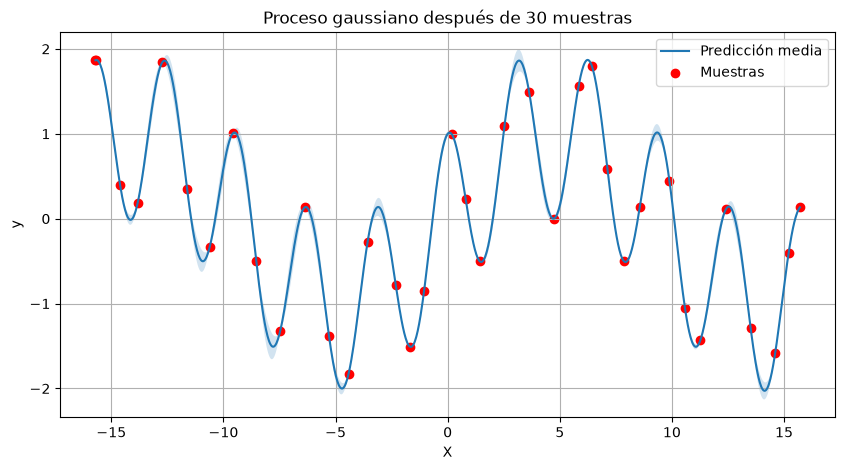

In [98]:
# Graficamos el proceso gaussiano después de 30 muestras

gp.fit(X, y)
y_pred, desv = gp.predict(X_new, return_std=True)

y_upper = y_pred + 2*desv
y_lower = y_pred - 2*desv

plt.figure(figsize=(10, 5))
plt.plot(X_new.ravel(), y_pred, label="Predicción media")
plt.fill_between(X_new.ravel(), y_lower, y_upper, alpha=0.2)
plt.scatter(X.ravel(), y.ravel(), color="red", label="Muestras")
plt.xlabel("X")
plt.ylabel("y")
plt.title("Proceso gaussiano después de 30 muestras")
plt.grid(True)
plt.legend()
plt.show()

### Actividad

1. Modificar el comportamiento de selección para elegir el máximo de las predicciones como el siguiente punto.
2. Modificar el comportamiento de selección para elegir el mínimo de las predicciones como el siguiente punto.

In [99]:
# Seleccionamos el máximo de las predicciones

np.random.seed(67)

X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape(-1, 1)
y = f(X)

for i in range(30):

    gp.fit(X, y)

    y_pred, desv = gp.predict(X_new, return_std=True)

    indice = np.argmax(y_pred)

    X_next = X_new[indice].reshape(1, -1)
    y_next = f(X_next)

    X = np.vstack((X, X_next))
    y = np.vstack((y, y_next))

print("Máximo encontrado:", np.max(y))
print("Posición:", X[np.argmax(y), 0])

/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 4 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda

Máximo encontrado: 1.8694176347701237
Posición: 6.242303721096835


/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 6 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)


In [100]:
# Guardamos los resultados del máximo

X_max = X.copy()
y_max = y.copy()

In [101]:
# Seleccionamos el mínimo de las predicciones

np.random.seed(67)

X = np.random.uniform(-5*np.pi, 5*np.pi, 6).reshape(-1, 1)
y = f(X)

for i in range(30):

    gp.fit(X, y)

    y_pred, desv = gp.predict(X_new, return_std=True)

    indice = np.argmin(y_pred)

    X_next = X_new[indice].reshape(1, -1)
    y_next = f(X_next)

    X = np.vstack((X, X_next))
    y = np.vstack((y, y_next))

print("Mínimo encontrado:", np.min(y))
print("Posición:", X[np.argmin(y), 0])

/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 18 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 9 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 13 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anacon

Mínimo encontrado: -1.5096232353028822
Posición: 11.085199303207226


/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 7 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 10 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/_gpr.py:667: ConvergenceWarning: lbfgs failed to converge after 8 iteration(s) (status=2):
ABNORMAL: 

You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
  _check_optimize_result("lbfgs", opt_res)
/opt/anacond

In [102]:
# Guardamos los resultados del mínimo

X_min = X.copy()
y_min = y.copy()

In [103]:
# Comparamos los resultados de los tres métodos

resultados = pd.DataFrame({
    'Método': ['Incertidumbre', 'Máximo', 'Mínimo'],
    'Valor máximo': [np.max(y_incertidumbre), np.max(y_max), np.max(y_min)],
    'Valor mínimo': [np.min(y_incertidumbre), np.min(y_max), np.min(y_min)],
    'Muestras': [len(y_incertidumbre), len(y_max), len(y_min)]
})

resultados

,Método,Valor máximo,Valor mínimo,Muestras
0,Incertidumbre,1.869242,-1.827216,36
1,Máximo,1.869418,-1.427178,36
2,Mínimo,1.562399,-1.509623,36


In [124]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF

In [133]:
# Datos
data = pd.read_csv("Default.csv")
data.head()

,default,student,balance,income
0,No,No,729.526495,44361.625074
1,No,Yes,817.180407,12106.134700
2,No,No,1073.549164,31767.138947
3,No,No,529.250605,35704.493935
4,No,No,785.655883,38463.495879


In [134]:
X = data.drop(columns=["default"])
y = data["default"].map({"No": 0, "Yes": 1})

In [135]:
# Student a numérica
X = X.copy()
X["student"] = X["student"].map({"No": 0, "Yes": 1})

print(X.head())
print(y.value_counts())

   student      balance        income
0        0   729.526495  44361.625074
1        1   817.180407  12106.134700
2        0  1073.549164  31767.138947
3        0   529.250605  35704.493935
4        0   785.655883  38463.495879
default
0    9667
1     333
Name: count, dtype: int64


In [136]:
# Función objetivo

def objetivo(H):

    C = H[0]
    gamma = H[1]
    global X
    global y

    # Crear modelo
    modelo = Pipeline([
        ("scaler", StandardScaler()),
        ("svc", SVC(C=C, gamma=gamma, kernel="rbf"))
    ])

    # Evaluar modelo
    score = cross_val_score(
        modelo,
        X,
        y,
        cv=5,
        scoring="roc_auc"
    )

    return np.mean(score)

In [137]:
objetivo([1, 0.1])

np.float64(0.76127997937806)

In [138]:
# Muestras iniciales
np.random.seed(42)

H_inicial = []
s_inicial = []

for i in range(5):

    C = np.random.uniform(0.1, 10)
    gamma = np.random.uniform(0.001, 1)
    H = [C, gamma]
    s = objetivo(H)

    H_inicial.append(H)
    s_inicial.append(s)

In [139]:
# Proceso gaussiano

kernel = 1 * RBF(length_scale=1)

gp = GaussianProcessRegressor(
    kernel=kernel,
    n_restarts_optimizer=10,
    normalize_y=True
)

In [140]:
# Opt bayesiana
for i in range(30):

    # Gaussiano
    gp.fit(np.array(H_inicial), np.array(s_inicial))

    # Hiperparámetros simulados
    H_sim = []

    for j in range(100):

        C = np.random.uniform(0.1, 10)
        gamma = np.random.uniform(0.001, 1)

        H_sim.append([C, gamma])

    # Estimar los resultados
    y_pred, desv = gp.predict(
        np.array(H_sim),
        return_std=True
    )

    # Seleccionar el máximo de y + 2 desviaciones
    y_upper = y_pred + 2 * desv

    indice = np.argmax(y_upper)

    H = H_sim[indice]

    # Evaluar la función objetivo
    s = objetivo(H)

    # Actualizar las muestras
    H_inicial.append(H)
    s_inicial.append(s)

    print("Iteración:", i + 1, "ROC-AUC:", s)

Iteración: 1 ROC-AUC: 0.7476508304909879
Iteración: 2 ROC-AUC: 0.7821012754774845
Iteración: 3 ROC-AUC: 0.819463980330468
Iteración: 4 ROC-AUC: 0.7830494907796037
Iteración: 5 ROC-AUC: 0.7579897788165056
Iteración: 6 ROC-AUC: 0.7995126979980726
Iteración: 7 ROC-AUC: 0.7683170207562217
Iteración: 8 ROC-AUC: 0.7436169656410714
Iteración: 9 ROC-AUC: 0.8265709170014585
Iteración: 10 ROC-AUC: 0.864459757869367


/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Iteración: 11 ROC-AUC: 0.750327413616453
Iteración: 12 ROC-AUC: 0.770354690954784
Iteración: 13 ROC-AUC: 0.8329393727265458
Iteración: 14 ROC-AUC: 0.8080957776175135
Iteración: 15 ROC-AUC: 0.7687065109710446
Iteración: 16 ROC-AUC: 0.7703156798958414
Iteración: 17 ROC-AUC: 0.874224570488467
Iteración: 18 ROC-AUC: 0.8038570051213153


/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Iteración: 19 ROC-AUC: 0.7539795879638346
Iteración: 20 ROC-AUC: 0.7591613569233958
Iteración: 21 ROC-AUC: 0.7989707803587676
Iteración: 22 ROC-AUC: 0.8676071200030705
Iteración: 23 ROC-AUC: 0.7684893905904623
Iteración: 24 ROC-AUC: 0.8159262328800356
Iteración: 25 ROC-AUC: 0.8783132990868887
Iteración: 26 ROC-AUC: 0.8496481913541686
Iteración: 27 ROC-AUC: 0.8724926789862415
Iteración: 28 ROC-AUC: 0.8216776437439155
Iteración: 29 ROC-AUC: 0.8533640981404499


/opt/anaconda3/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__length_scale is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


Iteración: 30 ROC-AUC: 0.8210799458402782


In [141]:
# Obtenemos los mejores hiperparámetros
indice = np.argmax(s_inicial)

mejor_H = H_inicial[indice]
mejor_auc = s_inicial[indice]

print("Mejor C:", mejor_H[0])
print("Mejor gamma:", mejor_H[1])
print("Mejor ROC-AUC:", mejor_auc)

Mejor C: 7.249939376869098
Mejor gamma: 0.17498253570300093
Mejor ROC-AUC: 0.8783132990868887
